# NB01 - Praproses dan Seleksi Citra Berdasarkan Confusion Line

Notebook ini menyiapkan seluruh kelas buah kecuali `000neg`, menghapus duplikat di dalam kelas, menyeragamkan ukuran citra, lalu mengukur kedekatan warna representatif dari seluruh piksel citra terhadap garis confusion protan dan deutan. Keputusan ambiguitas dibuat pada tingkat citra. Ringkasan per kelas memakai distribusi jarak, bukan hanya rata-rata.

Urutan: inventarisasi, deduplikasi, resize, sampling piksel seluruh citra, analisis confusion line per citra, filter citra dan kelas, undersampling per kelas untuk tiap tipe CVD, lalu penyeimbangan jumlah akhir antar keluarga CVD. Kuota akhir protan dan deutan sama dengan jumlah yang lebih kecil dari kedua keluarga; pemilihan tambahan hanya mengurangi keluarga yang lebih besar.

Folder hasil seleksi berbentuk `output/confusion_line_filtered/protan/apple_101.png` dan `output/confusion_line_filtered/deutan/apple_101.png`. Satu citra dapat masuk ke kedua folder jika memenuhi kriteria keduanya.


Versi ini sengaja tidak melakukan segmentasi. Warna latar ikut masuk ke analisis, sehingga hasilnya menggambarkan palet seluruh citra, bukan warna buah saja.


In [1]:
%pip install opencv-python-headless numpy pillow imagehash pandas matplotlib -q

Note: you may need to restart the kernel to use updated packages.


## Tahap 1 - Setup dan Konfigurasi


In [ ]:
from __future__ import annotations

import json
import random
import re
import shutil
import sys
import time
from pathlib import Path

import cv2
import imagehash
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

CORE_CANDIDATES = [Path.cwd() / "core", *[p / "core" for p in Path.cwd().parents]]
CORE_DIR = next((candidate for candidate in CORE_CANDIDATES if (candidate / "utils.py").exists()), None)
if CORE_DIR is None:
    raise FileNotFoundError("Folder core/utils.py tidak ditemukan")
if str(CORE_DIR) not in sys.path:
    sys.path.insert(0, str(CORE_DIR))
from utils import find_research_root, sha256_file, write_csv

RESEARCH_ROOT = find_research_root("datasets/raw/fruits")
RAW_DATASET_DIR = RESEARCH_ROOT / "datasets" / "raw" / "fruits"
OUTPUT_DIR = RESEARCH_ROOT / "notebooks" /"tanpa_segmentasi" / "01" / "output"
PROCESSED_DIR = RESEARCH_ROOT / "datasets" / "processed" / "tanpa_segmentasi"
CONFUSION_OUTPUT_DIR = OUTPUT_DIR / "confusion_line_filtered"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

SUBSET = "train"
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}
PHASH_THRESHOLD = 4
OUTPUT_SIZE = 512
COLOR_SAMPLES_PER_IMAGE = 1000
KMEANS_CLUSTERS = 4
RANDOM_SEED = 42

# Copunctal points in CIE 1931 xy, reported in Tsekouras et al. (2021), Figure 1.
COPUNCTAL_POINTS = {
    "protan": (0.763, 0.236),
    "deutan": (1.4, -0.4),
}

ALL_RAW_CLASSES = sorted(
    directory.name for directory in RAW_DATASET_DIR.iterdir()
    if directory.is_dir() and directory.name != "000neg" and (directory / SUBSET).exists()
)
if not ALL_RAW_CLASSES:
    raise RuntimeError("Tidak ditemukan kelas buah selain 000neg.")
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
print(f"Kelas buah yang diproses: {len(ALL_RAW_CLASSES)}")


Kelas buah yang diproses: 19


## Tahap 2 - Inventarisasi Seluruh Kelas Buah


In [3]:
def list_images(directory: Path) -> list[Path]:
    return sorted(
        path for path in directory.rglob("*")
        if path.is_file() and path.suffix.lower() in VALID_EXTENSIONS
    )

inventory_rows = []
for source_class in ALL_RAW_CLASSES:
    class_dir = RAW_DATASET_DIR / source_class / SUBSET
    images = list_images(class_dir)
    inventory_rows.append({
        "source_class": source_class,
        "subset": SUBSET,
        "raw_image_count": len(images),
        "source_directory": str(class_dir),
    })
inventory = pd.DataFrame(inventory_rows)
if inventory.empty or (inventory["raw_image_count"] == 0).any():
    raise RuntimeError("Ada kelas buah tanpa citra pada subset yang dipilih.")
print(inventory.to_string(index=False))
print(f"Total kelas: {len(inventory)}")
print(f"Total citra raw tanpa 000neg: {int(inventory['raw_image_count'].sum())}")


  source_class subset  raw_image_count                                                           source_directory
      001apple  train              418       C:\colorblind_simulation\research\datasets\raw\fruits\001apple\train
     002orange  train              432      C:\colorblind_simulation\research\datasets\raw\fruits\002orange\train
       003pear  train              268        C:\colorblind_simulation\research\datasets\raw\fruits\003pear\train
     004tomato  train              411      C:\colorblind_simulation\research\datasets\raw\fruits\004tomato\train
 005strawberry  train              450  C:\colorblind_simulation\research\datasets\raw\fruits\005strawberry\train
     006banana  train              394      C:\colorblind_simulation\research\datasets\raw\fruits\006banana\train
 007watermelon  train              239  C:\colorblind_simulation\research\datasets\raw\fruits\007watermelon\train
       008kiwi  train              311        C:\colorblind_simulation\research\datasets

## Tahap 3 - Deduplikasi dan Resize

Deduplikasi pHash dilakukan per kelas sebelum pengukuran warna agar citra berulang tidak memperbesar bobot distribusi. Citra unik lalu dipotong persegi dari tengah dan diubah ke ukuran seragam, mengikuti tahapan praproses yang sudah ada. Semua kelas buah selain `000neg` diproses; belum ada kelas yang dikeluarkan berdasarkan nama atau hue.


In [4]:
def compute_phash(image_path: Path) -> imagehash.ImageHash:
    with Image.open(image_path) as image:
        return imagehash.phash(image)


def deduplicate_images(
    image_paths: list[Path],
    threshold: int = PHASH_THRESHOLD,
) -> tuple[list[Path], list[tuple[Path, Path, int]]]:
    kept: list[Path] = []
    kept_hashes: list[imagehash.ImageHash] = []
    duplicates: list[tuple[Path, Path, int]] = []
    for path in image_paths:
        current_hash = compute_phash(path)
        match = next(
            ((existing_path, existing_hash) for existing_path, existing_hash in zip(kept, kept_hashes)
             if current_hash - existing_hash <= threshold),
            None,
        )
        if match is None:
            kept.append(path)
            kept_hashes.append(current_hash)
        else:
            existing_path, existing_hash = match
            duplicates.append((path, existing_path, current_hash - existing_hash))
    return kept, duplicates


def center_crop_resize(source_path: Path, destination_path: Path, size: int = OUTPUT_SIZE) -> None:
    image = cv2.imread(str(source_path), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError("Citra tidak dapat dibaca oleh OpenCV")
    height, width = image.shape[:2]
    edge = min(height, width)
    top, left = (height - edge) // 2, (width - edge) // 2
    cropped = image[top:top + edge, left:left + edge]
    resized = cv2.resize(cropped, (size, size), interpolation=cv2.INTER_AREA)
    destination_path.parent.mkdir(parents=True, exist_ok=True)
    if not cv2.imwrite(str(destination_path), resized):
        raise IOError("Citra hasil tidak dapat ditulis")


prepared_rows: list[dict] = []
duplicate_records: list[dict] = []
error_rows: list[dict] = []
for source_class in ALL_RAW_CLASSES:
    source_images = list_images(RAW_DATASET_DIR / source_class / SUBSET)
    try:
        unique_images, duplicates = deduplicate_images(source_images)
    except Exception as error:
        error_rows.append({"stage": "deduplication", "source_class": source_class, "source_path": "", "error": str(error)})
        continue
    for duplicate_path, kept_path, distance in duplicates:
        duplicate_records.append({
            "source_class": source_class,
            "duplicate_file": duplicate_path.name,
            "kept_file": kept_path.name,
            "hamming_distance": int(distance),
        })
    for source_path in unique_images:
        output_path = PROCESSED_DIR / source_class / f"{source_path.stem}.png"
        try:
            started = time.perf_counter()
            center_crop_resize(source_path, output_path)
            prepared_rows.append({
                "subset": SUBSET,
                "source_class": source_class,
                "source_file_name": source_path.name,
                "source_path": str(source_path),
                "output_file_name": output_path.name,
                "output_path": str(output_path),
                "output_sha256": sha256_file(output_path),
                "processing_seconds": round(time.perf_counter() - started, 6),
            })
        except Exception as error:
            error_rows.append({"stage": "preprocessing", "source_class": source_class, "source_path": str(source_path), "error": str(error)})

prepared_manifest = pd.DataFrame(prepared_rows)
if prepared_manifest.empty:
    raise RuntimeError("Tidak ada citra yang berhasil dideduplikasi dan di-resize.")
prepared_manifest = prepared_manifest.sort_values(["source_class", "source_file_name"]).reset_index(drop=True)
print(f"Citra unik yang berhasil di-resize: {len(prepared_manifest)}")
print(f"Duplikat yang dihapus: {len(duplicate_records)}")


Citra unik yang berhasil di-resize: 4692
Duplikat yang dihapus: 178


## Tahap 4 - Analisis Confusion Line pada Seluruh Piksel Citra

Metode citra utama mengikuti Tsekouras et al. (2021), yang mengekstrak warna representatif dari citra, memetakannya ke diagram kromatisitas CIE 1931, dan menguji kedekatannya pada confusion line. Studi tersebut juga menguji metode citranya pada koleksi McGill *Flowers and Fruits*, termasuk 52 citra buah. Persamaan jarak titik-ke-garis yang dipakai di sini adalah Persamaan 12 pada artikel itu:

\[
d(v,L)=\frac{|(x_{cp}-x_0)(y_0-v_y)-(x_0-v_x)(y_{cp}-y_0)|}{\sqrt{(x_{cp}-x_0)^2+(y_{cp}-y_0)^2}}
\]

`(x_cp, y_cp)` adalah copunctal point, `(x_0, y_0)` adalah warna pusat cluster yang membentuk garis, dan `(v_x, v_y)` adalah pusat cluster warna pembanding. Jarak dihitung dua arah untuk setiap pasangan pusat cluster; setiap nilai tetap memakai Persamaan 12. Median dan kuartil dari jarak pasangan menjadi ringkasan per citra. Jarak kecil berarti dua pusat warna lebih dekat pada confusion line yang sama menurut geometri yang dipakai, bukan ambang diagnosis klinis.

Pada versi ini tidak ada mask foreground. Piksel dari seluruh citra hasil resize menjadi populasi sampling untuk K-means, sehingga warna latar dapat memengaruhi pusat warna dan jarak confusion line. K-means `K=4` merangkum warna citra dan dipertahankan agar tahapan pengukuran jarak tetap sebanding dengan notebook utama.

Sumber: [Tsekouras et al. (2021), *A Novel Approach to Image Recoloring for Color Vision Deficiency*, Sensors 21(8), 2740, Bagian 3 dan Persamaan 12](https://doi.org/10.3390/s21082740). Penggunaan garis confusion sebagai ukuran persepsi didukung oleh [studi validasi tes warna digital (2024)](https://www.mdpi.com/2075-4418/14/4/396). Tanpa peserta CVD, keluaran NB01 adalah kesesuaian geometris dengan model confusion line, bukan bukti langsung tentang persepsi semua penderita.


In [6]:
def srgb_to_linear(rgb: np.ndarray) -> np.ndarray:
    """Decode normalized sRGB values using the IEC 61966-2-1 transfer function."""
    values = np.clip(np.asarray(rgb, dtype=np.float64), 0.0, 1.0)
    return np.where(values <= 0.04045, values / 12.92, ((values + 0.055) / 1.055) ** 2.4)


def rgb_to_cie_xy(rgb: np.ndarray) -> np.ndarray:
    """Convert sRGB colors to CIE 1931 xy under the sRGB D65 matrix."""
    linear = srgb_to_linear(rgb)
    matrix = np.array([
        [0.4124564, 0.3575761, 0.1804375],
        [0.2126729, 0.7151522, 0.0721750],
        [0.0193339, 0.1191920, 0.9503041],
    ])
    xyz = linear @ matrix.T
    totals = xyz.sum(axis=1)
    valid = totals > np.finfo(np.float64).eps
    xy = np.full((len(xyz), 2), np.nan, dtype=np.float64)
    xy[valid] = xyz[valid, :2] / totals[valid, None]
    return xy


def point_to_confusion_line_distance(
    point: np.ndarray,
    line_point: np.ndarray,
    copunctal_point: tuple[float, float],
) -> float:
    """Calculate point-to-line distance using Equation 12 from Tsekouras et al. (2021)."""
    x_cp, y_cp = copunctal_point
    x_0, y_0 = line_point
    v_x, v_y = point
    numerator = abs((x_cp - x_0) * (y_0 - v_y) - (x_0 - v_x) * (y_cp - y_0))
    denominator = np.sqrt((x_cp - x_0) ** 2 + (y_cp - y_0) ** 2)
    return float(numerator / denominator) if denominator > 0 else np.nan


def analyze_image_confusion(image_path: str, rng: np.random.Generator) -> dict:
    """Measure confusion-line distances from representative colors of the full image."""
    image_bgr = cv2.imread(image_path, cv2.IMREAD_COLOR)
    if image_bgr is None:
        raise ValueError("Citra hasil resize tidak dapat dibaca")

    image_pixels = image_bgr.reshape(-1, 3)
    sample_count = min(COLOR_SAMPLES_PER_IMAGE, len(image_pixels))
    sample_indices = rng.choice(len(image_pixels), size=sample_count, replace=False)
    sample_rgb = image_pixels[sample_indices, ::-1].astype(np.float32) / 255.0
    cv2.setRNGSeed(RANDOM_SEED)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 50, 0.2)
    _, _, centers = cv2.kmeans(
        sample_rgb.reshape(-1, 3),
        KMEANS_CLUSTERS,
        None,
        criteria,
        3,
        cv2.KMEANS_PP_CENTERS,
    )
    center_xy = rgb_to_cie_xy(centers)
    if not np.isfinite(center_xy).all():
        raise ValueError("Pusat warna tidak dapat dipetakan ke CIE xy")

    result = {
        "sampled_pixel_count": int(sample_count),
        "key_color_count": int(len(center_xy)),
    }
    for cvd, copunctal_point in COPUNCTAL_POINTS.items():
        distances = []
        for first in range(len(center_xy)):
            for second in range(first + 1, len(center_xy)):
                distances.append(point_to_confusion_line_distance(center_xy[second], center_xy[first], copunctal_point))
                distances.append(point_to_confusion_line_distance(center_xy[first], center_xy[second], copunctal_point))
        distances = np.asarray(distances, dtype=np.float64)
        distances = distances[np.isfinite(distances)]
        if distances.size == 0:
            raise ValueError(f"Tidak ada jarak pasangan warna valid untuk {cvd}")
        result.update({
            f"{cvd}_pair_distance_mean": float(np.mean(distances)),
            f"{cvd}_pair_distance_median": float(np.median(distances)),
            f"{cvd}_pair_distance_q25": float(np.quantile(distances, 0.25)),
            f"{cvd}_pair_distance_q75": float(np.quantile(distances, 0.75)),
        })
    return result


rng = np.random.default_rng(RANDOM_SEED)
image_records = []
for row in prepared_manifest.itertuples(index=False):
    try:
        metrics = analyze_image_confusion(row.output_path, rng)
        image_records.append({
            "subset": row.subset,
            "source_class": row.source_class,
            "source_file_name": row.source_file_name,
            "source_path": row.source_path,
            "output_file_name": row.output_file_name,
            "output_path": row.output_path,
            "output_sha256": row.output_sha256,
            **metrics,
            "analysis_status": "ok",
            "analysis_error": "",
        })
    except Exception as error:
        image_records.append({
            "subset": row.subset,
            "source_class": row.source_class,
            "source_file_name": row.source_file_name,
            "source_path": row.source_path,
            "output_file_name": row.output_file_name,
            "output_path": row.output_path,
            "output_sha256": row.output_sha256,
            "analysis_status": "error",
            "analysis_error": str(error),
        })

image_analysis = pd.DataFrame(image_records)
valid_analysis = image_analysis[image_analysis["analysis_status"] == "ok"].copy()
if valid_analysis.empty:
    error_counts = image_analysis["analysis_error"].value_counts().head(5).to_dict()
    raise RuntimeError(
        "Tidak ada citra yang berhasil dianalisis dengan confusion line. "
        f"Penyebab utama: {error_counts}"
    )
class_summary_rows = []
for source_class, group in valid_analysis.groupby("source_class"):
    summary = {"source_class": source_class, "image_count": len(group)}
    for cvd in COPUNCTAL_POINTS:
        metric = f"{cvd}_pair_distance_median"
        summary.update({
            f"{cvd}_distance_mean_across_images": float(group[metric].mean()),
            f"{cvd}_distance_median_across_images": float(group[metric].median()),
            f"{cvd}_distance_q25_across_images": float(group[metric].quantile(0.25)),
            f"{cvd}_distance_q75_across_images": float(group[metric].quantile(0.75)),
        })
    class_summary_rows.append(summary)
class_confusion_summary = pd.DataFrame(class_summary_rows)
if class_confusion_summary.empty:
    raise RuntimeError("Tidak ada ringkasan kelas yang dapat dihitung.")
print(f"Citra dianalisis: {len(valid_analysis)} dari {len(prepared_manifest)}")
print(f"Citra gagal analisis: {len(image_analysis) - len(valid_analysis)}")


Citra dianalisis: 4692 dari 4692
Citra gagal analisis: 0


### Distribusi Jarak per Kelas

Boxplot menunjukkan sebaran jarak confusion line seluruh citra pada tiap kelas. Karena versi ini tidak memisahkan objek dari latar, interpretasi jarak merujuk pada warna gabungan buah dan latar.


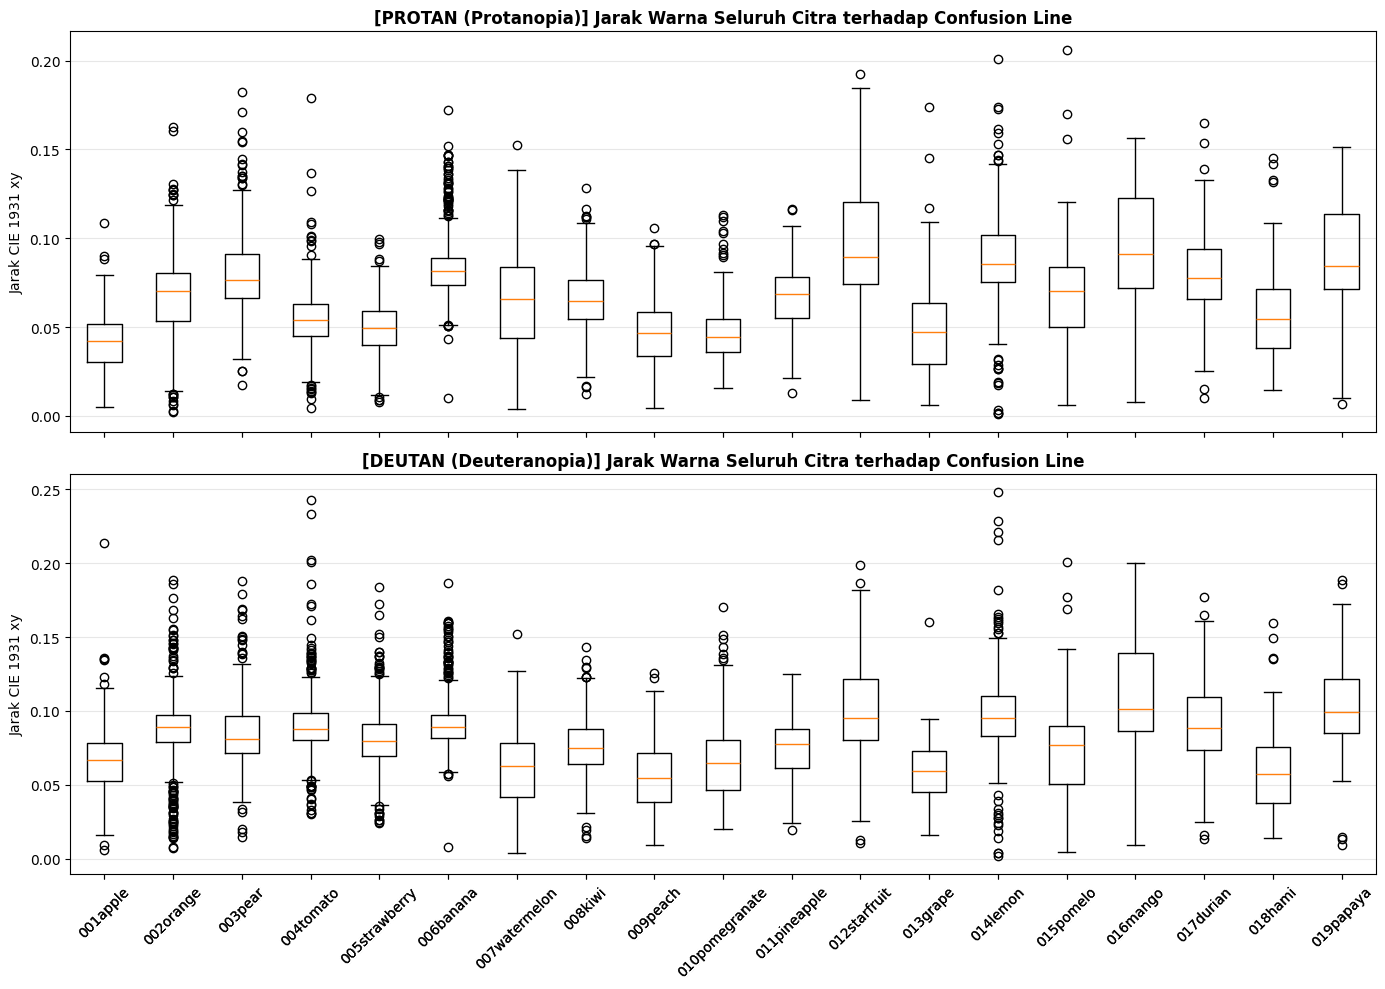

=== RINGKASAN CONFUSION LINE PER TIPE CVD ===


,source_class,image_count,mean_median_distance_across_images,cvd_family
0,001apple,398,0.066703,deutan
1,002orange,424,0.087195,deutan
2,003pear,263,0.085692,deutan
3,004tomato,404,0.091174,deutan
4,005strawberry,441,0.081347,deutan
5,006banana,372,0.093184,deutan
6,007watermelon,233,0.059234,deutan
7,008kiwi,301,0.076862,deutan
8,009peach,400,0.055361,deutan
9,010pomegranate,261,0.066682,deutan


In [7]:
from IPython.display import display

required_analysis_state = ['valid_analysis', 'class_confusion_summary', 'COPUNCTAL_POINTS']
missing_analysis_state = [name for name in required_analysis_state if name not in globals()]
if missing_analysis_state:
    raise RuntimeError(
        "Jalankan semua sel notebook dari atas. Variabel belum tersedia: "
        + ", ".join(missing_analysis_state)
    )

cvd_titles = {
    "protan": "PROTAN (Protanopia)",
    "deutan": "DEUTAN (Deuteranopia)"
}
fig, axes = plt.subplots(len(COPUNCTAL_POINTS), 1, figsize=(14, 10), sharex=True)
if len(COPUNCTAL_POINTS) == 1:
    axes = [axes]
for ax, cvd in zip(axes, COPUNCTAL_POINTS):
    metric = f"{cvd}_pair_distance_median"
    grouped = valid_analysis.groupby("source_class")
    plot_data = [group[metric].to_numpy() for _, group in grouped]
    labels = [name for name, _ in grouped]
    ax.boxplot(plot_data, tick_labels=labels, showfliers=True)
    ax.set_title(f"[{cvd_titles.get(cvd, cvd.upper())}] Jarak Warna Seluruh Citra terhadap Confusion Line", fontweight="bold")
    ax.set_ylabel("Jarak CIE 1931 xy")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

tidy_summary_df = class_confusion_summary.melt(
    id_vars=["source_class", "image_count"],
    value_vars=[column for column in class_confusion_summary.columns if column.endswith("_distance_mean_across_images")],
    var_name="cvd_metric",
    value_name="mean_median_distance_across_images",
)
tidy_summary_df["cvd_family"] = tidy_summary_df["cvd_metric"].str.split("_").str[0]
tidy_summary_df = tidy_summary_df.drop(columns="cvd_metric")
print("=== RINGKASAN CONFUSION LINE PER TIPE CVD ===")
display(tidy_summary_df.sort_values(["cvd_family", "source_class"]).reset_index(drop=True))


Sumber diagram: c:\colorblind_simulation\research\notebooks\tanpa_segmentasi\01\output\confusion_line_image_analysis.csv
Contoh: 001apple / 1.png


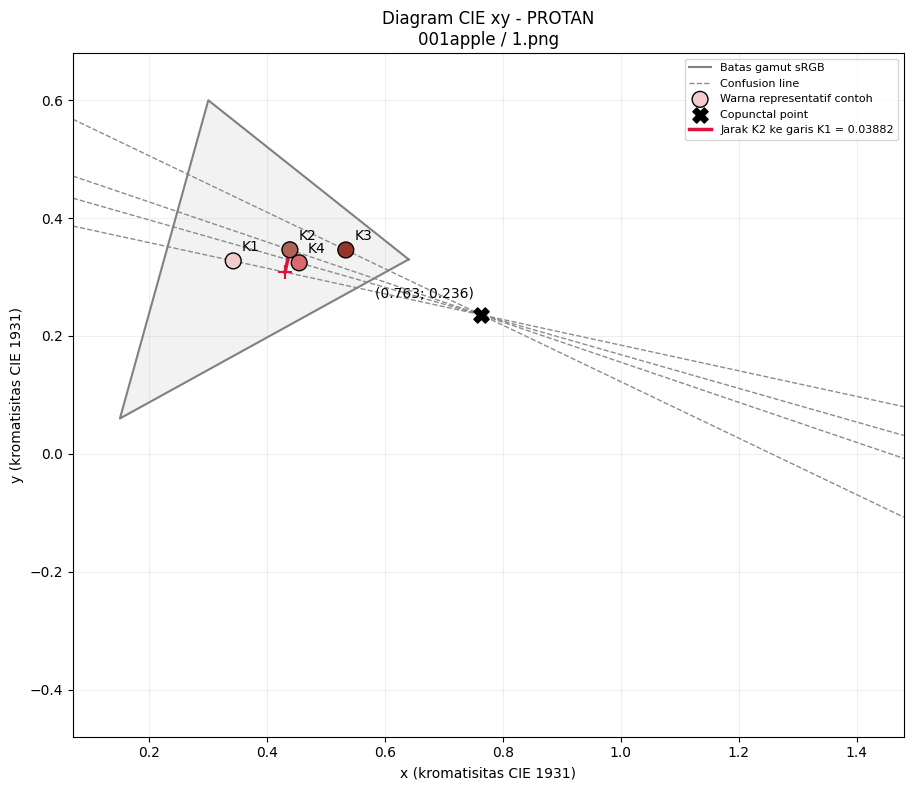

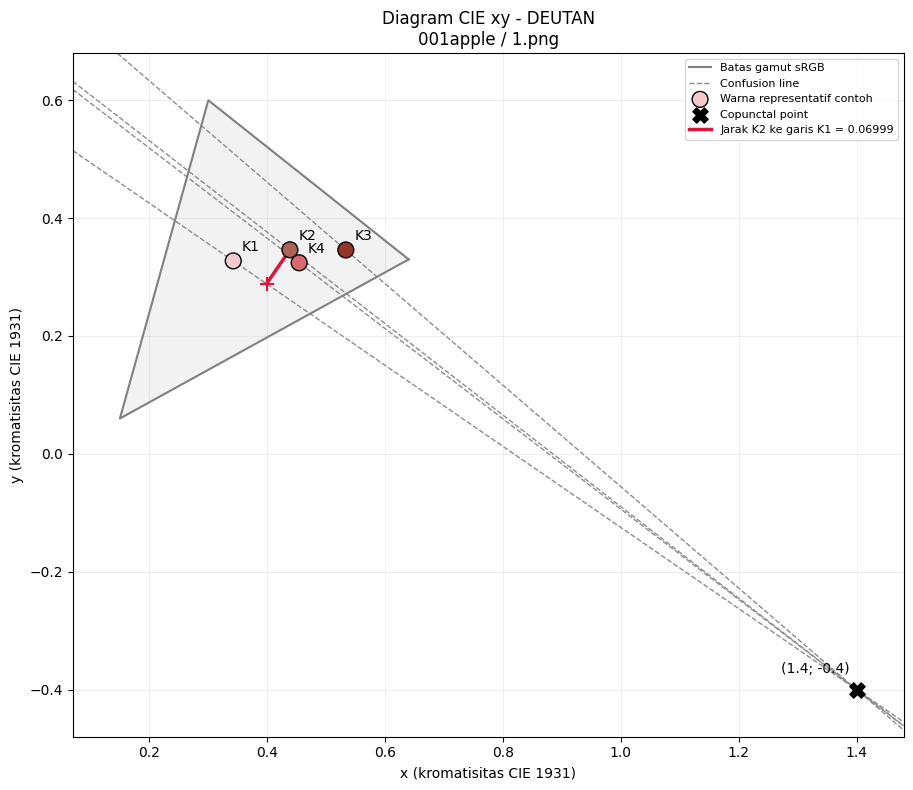

In [4]:
# Pilih contoh citra untuk kedua diagram tanpa mengubah data analisis.
XY_EXAMPLE_INDEX = 0


def show_confusion_xy_example(example_index: int = 0) -> None:
    """Tampilkan geometri dua tipe dari sampel lokal, tanpa mengubah hasil seleksi."""
    import json
    from pathlib import Path
    import cv2
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    # Baca state aktif jika tersedia; jika tidak, muat salinan laporan tersimpan.
    roots = [Path.cwd(), *Path.cwd().parents]
    report_candidates = []
    if "OUTPUT_DIR" in globals():
        report_candidates.append(Path(globals()["OUTPUT_DIR"]) / "confusion_line_image_analysis.csv")
    for root in roots:
        for suffix in (
            "research/notebooks/tanpa_segmentasi/01/output",
            "research/notebooks/01/output/tanpa_segmentasi",
            "notebooks/tanpa_segmentasi/01/output",
            "notebooks/01/output/tanpa_segmentasi",
            "output",
        ):
            report_candidates.append(root / suffix / "confusion_line_image_analysis.csv")
    report_path = next((path for path in report_candidates if path.is_file()), None)
    config = {}
    if "valid_analysis" in globals() and not globals()["valid_analysis"].empty:
        valid_analysis = globals()["valid_analysis"].copy()
        print("Sumber diagram: salinan data pada sesi aktif.")
        config = {key: globals()[key] for key in (
            "COPUNCTAL_POINTS", "COLOR_SAMPLES_PER_IMAGE", "KMEANS_CLUSTERS", "RANDOM_SEED"
        ) if key in globals()}
    else:
        if report_path is None:
            raise FileNotFoundError("Laporan confusion_line_image_analysis.csv tidak ditemukan. Buka notebook dari folder proyek yang memiliki hasil NB01.")
        saved = pd.read_csv(report_path)
        valid_analysis = saved.loc[saved["analysis_status"].eq("ok")].copy()
        summary_path = report_path.with_name("dataset_preparation_summary.json")
        if summary_path.is_file():
            summary = json.loads(summary_path.read_text(encoding="utf-8"))
            config = {
                "COPUNCTAL_POINTS": summary["copunctal_points_cie1931_xy"],
                "COLOR_SAMPLES_PER_IMAGE": summary["color_samples_per_image"],
                "KMEANS_CLUSTERS": summary["kmeans_clusters"],
            }
        print(f"Sumber diagram: {report_path}")
    COPUNCTAL_POINTS = config.get("COPUNCTAL_POINTS", {"protan": (0.763, 0.236), "deutan": (1.4, -0.4)})
    COLOR_SAMPLES_PER_IMAGE = int(config.get("COLOR_SAMPLES_PER_IMAGE", 1000))
    KMEANS_CLUSTERS = int(config.get("KMEANS_CLUSTERS", 4))
    RANDOM_SEED = int(config.get("RANDOM_SEED", 42))

    def srgb_to_linear(rgb: np.ndarray) -> np.ndarray:
        """Decode normalized sRGB values using the IEC 61966-2-1 transfer function."""
        values = np.clip(np.asarray(rgb, dtype=np.float64), 0.0, 1.0)
        return np.where(values <= 0.04045, values / 12.92, ((values + 0.055) / 1.055) ** 2.4)


    def rgb_to_cie_xy(rgb: np.ndarray) -> np.ndarray:
        """Convert sRGB colors to CIE 1931 xy under the sRGB D65 matrix."""
        linear = srgb_to_linear(rgb)
        matrix = np.array([
            [0.4124564, 0.3575761, 0.1804375],
            [0.2126729, 0.7151522, 0.0721750],
            [0.0193339, 0.1191920, 0.9503041],
        ])
        xyz = linear @ matrix.T
        totals = xyz.sum(axis=1)
        valid = totals > np.finfo(np.float64).eps
        xy = np.full((len(xyz), 2), np.nan, dtype=np.float64)
        xy[valid] = xyz[valid, :2] / totals[valid, None]
        return xy


    def point_to_confusion_line_distance(
        point: np.ndarray,
        line_point: np.ndarray,
        copunctal_point: tuple[float, float],
    ) -> float:
        """Calculate point-to-line distance using Equation 12 from Tsekouras et al. (2021)."""
        x_cp, y_cp = copunctal_point
        x_0, y_0 = line_point
        v_x, v_y = point
        numerator = abs((x_cp - x_0) * (y_0 - v_y) - (x_0 - v_x) * (y_cp - y_0))
        denominator = np.sqrt((x_cp - x_0) ** 2 + (y_cp - y_0) ** 2)
        return float(numerator / denominator) if denominator > 0 else np.nan


    if not 0 <= example_index < len(valid_analysis):
        raise ValueError(f"Indeks contoh harus berada pada 0 sampai {len(valid_analysis) - 1}.")

    row = valid_analysis.iloc[example_index]
    image_path = Path(str(row["output_path"]))
    if not image_path.is_file():
        # Perbaiki lokasi laporan lama jika folder proyek pernah dipindah.
        normalized = str(row["output_path"]).replace("\\", "/")
        relative = normalized.split("/research/", 1)[-1] if "/research/" in normalized else None
        if relative:
            relocated = [root / "research" / relative for root in roots]
            relocated += [root / relative for root in roots if root.name == "research"]
            image_path = next((path for path in relocated if path.is_file()), image_path)
    source_bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    if source_bgr is None:
        raise FileNotFoundError(f"Citra contoh tidak dapat dibaca: {row['output_path']}")

    # Generator lokal menjaga urutan sampling analisis sebelumnya tetap utuh.
    local_rng = np.random.default_rng(RANDOM_SEED)
    pixels = source_bgr.reshape(-1, 3)
    indices = local_rng.choice(len(pixels), min(COLOR_SAMPLES_PER_IMAGE, len(pixels)), replace=False)
    sample_rgb = pixels[indices, ::-1].astype(np.float32) / 255.0
    # Inisialisasi label lokal agar tidak memakai pengacakan global OpenCV.
    initial_labels = (np.arange(len(sample_rgb)) % KMEANS_CLUSTERS).astype(np.int32)
    local_rng.shuffle(initial_labels)
    _, _, centers_rgb = cv2.kmeans(
        sample_rgb, KMEANS_CLUSTERS, initial_labels.reshape(-1, 1),
        (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 50, 0.2),
        1, cv2.KMEANS_USE_INITIAL_LABELS,
    )
    centers_xy = rgb_to_cie_xy(centers_rgb)
    if not np.isfinite(centers_xy).all():
        raise ValueError("Warna contoh tidak memiliki koordinat xy yang valid; pilih citra lain.")

    # Batas gamut berasal dari konversi tiga warna primer sRGB yang sama.
    primary_xy = rgb_to_cie_xy(np.eye(3))
    triangle = np.vstack([primary_xy, primary_xy[0]])
    all_points = np.vstack([primary_xy, centers_xy, *COPUNCTAL_POINTS.values()])
    lower = all_points.min(axis=0) - 0.08
    upper = all_points.max(axis=0) + 0.08
    print("Contoh:", row["source_class"], "/", row["source_file_name"])

    for cvd, copunctal in COPUNCTAL_POINTS.items():
        cp = np.asarray(copunctal, dtype=float)
        fig, ax = plt.subplots(figsize=(10, 8))
        ax.fill(triangle[:, 0], triangle[:, 1], color="0.95", zorder=0)
        ax.plot(triangle[:, 0], triangle[:, 1], color="0.5", label="Batas gamut sRGB")
        for index, point in enumerate(centers_xy):
            ax.axline(cp, point, color="0.55", linestyle="--", linewidth=1,
                      label="Confusion line" if index == 0 else None, zorder=1)
            ax.annotate(f"K{index + 1}", point, xytext=(6, 7), textcoords="offset points")
        ax.scatter(centers_xy[:, 0], centers_xy[:, 1], c=np.clip(centers_rgb, 0, 1),
                   s=130, edgecolors="black", label="Warna representatif contoh", zorder=4)
        ax.scatter(*cp, marker="X", s=120, c="black", label="Copunctal point", zorder=4)
        ax.annotate(f"({cp[0]:g}; {cp[1]:g})", cp, xytext=(-5, 12),
                    textcoords="offset points", ha="right")

        # Proyeksi ortogonal ini hanya menggambar jarak titik ke garis acuan K1.
        anchor, point = centers_xy[:2]
        direction = cp - anchor
        projection = anchor + np.dot(point - anchor, direction) / np.dot(direction, direction) * direction
        distance = point_to_confusion_line_distance(point, anchor, tuple(cp))
        ax.plot([point[0], projection[0]], [point[1], projection[1]],
                color="crimson", linewidth=2.5, label=f"Jarak K2 ke garis K1 = {distance:.5f}", zorder=3)
        ax.scatter(*projection, marker="+", c="crimson", s=90, zorder=5)
        ax.set(xlim=(lower[0], upper[0]), ylim=(lower[1], upper[1]),
               xlabel="x (kromatisitas CIE 1931)", ylabel="y (kromatisitas CIE 1931)",
               title=f"Diagram CIE xy - {cvd.upper()}\n{row['source_class']} / {row['source_file_name']}")
        ax.set_aspect("equal", adjustable="box")
        ax.grid(alpha=0.2)
        ax.legend(loc="upper right", fontsize=8)
        fig.tight_layout()
        plt.show()


show_confusion_xy_example(XY_EXAMPLE_INDEX)


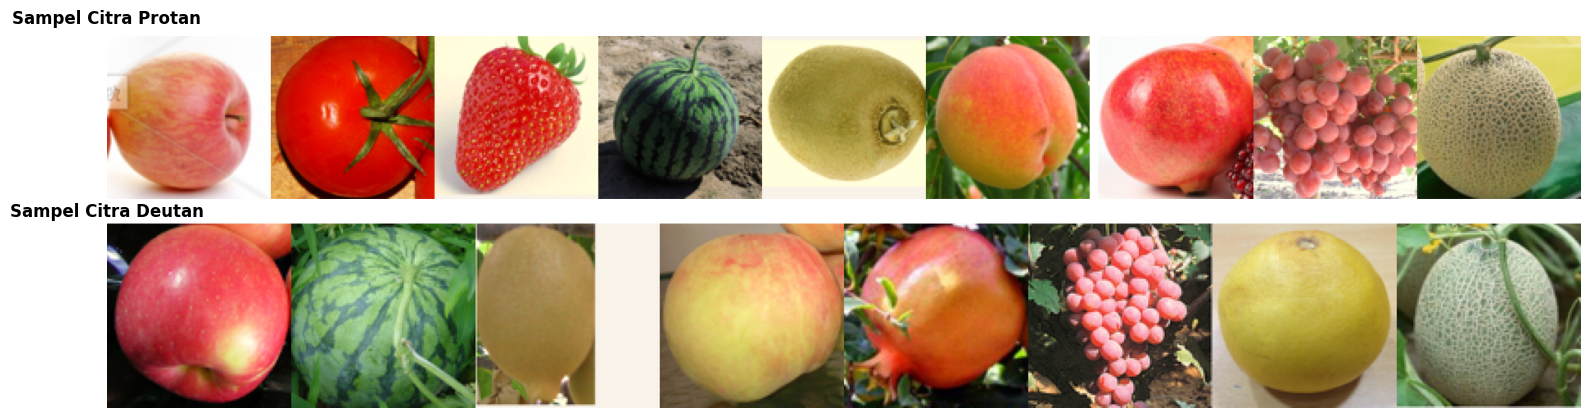

In [ ]:
SAMPLE_IMAGES_PER_CLASS = 1


def show_selected_cvd_samples(images_per_class: int = 1) -> None:
    """Baca manifest akhir dan satukan protan & deutan dalam 1 citra rapat tanpa jeda kosong."""
    from pathlib import Path
    import cv2 
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from PIL import Image

    if not isinstance(images_per_class, int) or images_per_class < 1:
        raise ValueError("Jumlah sampel per kelas harus berupa bilangan bulat positif.")

    roots = [Path.cwd(), *Path.cwd().parents]
    candidates = []
    if "OUTPUT_DIR" in globals():
        candidates.append(Path(globals()["OUTPUT_DIR"]) / "confusion_line_selected_by_cvd.csv")
    for root in roots:
        for suffix in (
            "research/notebooks/tanpa_segmentasi/01/output",
            "research/notebooks/01/output/tanpa_segmentasi",
            "notebooks/tanpa_segmentasi/01/output",
            "notebooks/01/output/tanpa_segmentasi",
            "output",
        ):
            candidates.append(root / suffix / "confusion_line_selected_by_cvd.csv")
    report_path = next((path for path in candidates if path.is_file()), None)
    if report_path is None:
        raise FileNotFoundError(
            "Manifest confusion_line_selected_by_cvd.csv belum ditemukan. "
            "Galeri memerlukan berkas hasil seleksi NB01 yang sudah tersimpan."
        )

    records = pd.read_csv(report_path)
    required = {"cvd_family", "source_class", "source_file_name", "output_path"}
    missing = required.difference(records.columns)
    if missing:
        raise ValueError("Kolom manifest tidak lengkap: " + ", ".join(sorted(missing)))

    def resolve_sample_path(stored_path: str) -> Path:
        path = Path(stored_path)
        if path.is_file():
            return path
        normalized = stored_path.replace("\\", "/")
        if "/research/" in normalized:
            relative = normalized.split("/research/", 1)[1]
            relocated = [root / "research" / relative for root in roots]
            relocated += [root / relative for root in roots if root.name == "research"]
            match = next((item for item in relocated if item.is_file()), None)
            if match is not None:
                return match
        return path

    stitched_strips = {}
    target_height = 200  # Tinggi standar setiap gambar per baris

    for cvd in ("protan", "deutan"):
        family = records.loc[records["cvd_family"].eq(cvd)].copy()
        if family.empty:
            continue

        chunks = [
            group.sort_values(["source_file_name", "output_path"]).sample(
                n=min(images_per_class, len(group)), random_state=42
            )
            for _, group in family.groupby("source_class", sort=True)
        ]
        samples = pd.concat(chunks, ignore_index=True)

        loaded_arrays = []
        for _, record in samples.iterrows():
            image_path = resolve_sample_path(str(record["output_path"]))
            try:
                with Image.open(image_path) as img:
                    rgb_img = img.convert("RGB")
                    # Samakan tinggi semua foto
                    new_width = int(rgb_img.width * (target_height / rgb_img.height))
                    rgb_img = rgb_img.resize((new_width, target_height), Image.Resampling.LANCZOS)
                    loaded_arrays.append(np.asarray(rgb_img))
            except (OSError, ValueError):
                continue

        if loaded_arrays:
            # Satukan rapat menyamping (horizontal)
            stitched_strips[cvd] = np.concatenate(loaded_arrays, axis=1)

    if "protan" in stitched_strips and "deutan" in stitched_strips:
        strip_protan = stitched_strips["protan"]
        strip_deutan = stitched_strips["deutan"]

        # Samakan total lebar (width) kedua strip agar simetris saat ditumpuk
        max_width = max(strip_protan.shape[1], strip_deutan.shape[1])

        def match_width(strip: np.ndarray, target_w: int) -> np.ndarray:
            if strip.shape[1] == target_w:
                return strip
            pil_strip = Image.fromarray(strip)
            new_h = int(strip.shape[0] * (target_w / strip.shape[1]))
            resized = pil_strip.resize((target_w, new_h), Image.Resampling.LANCZOS)
            return np.asarray(resized)

        strip_protan = match_width(strip_protan, max_width)
        strip_deutan = match_width(strip_deutan, max_width)

        # Garis pembatas tipis (misal putih setebal 8px) antar protan & deutan
        tebal_gap = 30
        gap = np.full((tebal_gap, max_width, 3), 255, dtype=np.uint8)

        # Gabungkan keduanya secara vertikal menjadi SATU matriks gambar utuh
        combined = np.vstack([strip_protan, gap, strip_deutan])

        # Tampilkan sebagai 1 gambar tanpa subplot terpisah
        fig, ax = plt.subplots(figsize=(16, 8))
        ax.imshow(combined)
        ax.axis("off")

        # Label sederhana di atas dan di tengah untuk penanda
        ax.text(0, -10, "Sampel Citra Protan", fontsize=12, fontweight="semibold", va="bottom", ha="center")
        y_label_deutan = strip_protan.shape[0] + tebal_gap
        ax.text(0, y_label_deutan - 4, "Sampel Citra Deutan", fontsize=12, fontweight="semibold", va="bottom", ha="center")

        fig.tight_layout()
        fig.savefig("sampel_cvd_protan_deutan.png", bbox_inches="tight", dpi=300)
        plt.show()


show_selected_cvd_samples(SAMPLE_IMAGES_PER_CLASS)

## Tahap 5 - Undersampling

Kelas dipertahankan untuk satu tipe CVD bila mean **dan** median jarak antarcitranya berada pada sisi jarak rendah menurut ambang Otsu. Kuartil tetap dilaporkan untuk memperlihatkan variasi, dan seleksi citra selanjutnya memakai ambang citra yang sama. Tahap pertama mengambil jumlah citra yang sama untuk setiap kelas yang memenuhi syarat dalam keluarga CVD tersebut. Tahap kedua menyamakan total protan dan deutan dengan mengambil sampel acak ber-seed tetap dari keluarga yang jumlahnya lebih besar. Jumlah kelas dan citra kandidat dapat berubah dibanding notebook utama karena warna latar ikut dihitung. Kuota akhir protan dan deutan tetap dihitung otomatis dari keluarga dengan jumlah kandidat lebih sedikit, sehingga total keduanya seimbang setelah tahap ini. Penyeimbangan tahap kedua tidak menjamin jumlah tiap kelas sama antar-CVD, dan citra yang sama dapat tercatat pada kedua keluarga bila lolos keduanya.


In [8]:
required_analysis_state = ['image_analysis', 'valid_analysis', 'class_confusion_summary', 'COPUNCTAL_POINTS']
missing_analysis_state = [name for name in required_analysis_state if name not in globals()]
if missing_analysis_state:
    raise RuntimeError(
        "Jalankan semua sel notebook dari atas. Variabel belum tersedia: "
        + ", ".join(missing_analysis_state)
    )

def otsu_lower_threshold(values: pd.Series) -> float:
    finite = np.asarray(values, dtype=np.float64)
    finite = finite[np.isfinite(finite)]
    if finite.size == 0:
        raise ValueError("Otsu memerlukan setidaknya satu nilai finite")
    minimum, maximum = float(finite.min()), float(finite.max())
    if maximum == minimum:
        return minimum
    scaled = np.rint((finite - minimum) * (255.0 / (maximum - minimum))).astype(np.uint8)
    threshold_u8, _ = cv2.threshold(scaled.reshape(-1, 1), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return minimum + float(threshold_u8) * (maximum - minimum) / 255.0


ambiguity_thresholds = {}
selected_classes_by_cvd: dict[str, list[str]] = {}
selected_rows_by_cvd: dict[str, pd.DataFrame] = {}
class_filter_records = []
for cvd in COPUNCTAL_POINTS:
    image_metric = f"{cvd}_pair_distance_median"
    class_mean = f"{cvd}_distance_mean_across_images"
    class_median = f"{cvd}_distance_median_across_images"
    threshold = otsu_lower_threshold(valid_analysis[image_metric])
    ambiguity_thresholds[cvd] = threshold
    class_confusion_summary[f"{cvd}_otsu_threshold"] = threshold
    class_confusion_summary[f"{cvd}_class_selected"] = (
        (class_confusion_summary[class_mean] <= threshold)
        & (class_confusion_summary[class_median] <= threshold)
    )
    selected_classes = class_confusion_summary.loc[
        class_confusion_summary[f"{cvd}_class_selected"], "source_class"
    ].tolist()
    selected_classes_by_cvd[cvd] = selected_classes
    candidates = valid_analysis[
        valid_analysis["source_class"].isin(selected_classes)
        & (valid_analysis[image_metric] <= threshold)
    ].copy()
    counts = candidates.groupby("source_class").size()
    eligible_classes = [name for name in selected_classes if name in counts.index and counts[name] > 0]
    candidates = candidates[candidates["source_class"].isin(eligible_classes)]
    if not candidates.empty:
        class_quota = int(candidates.groupby("source_class").size().min())
        sampled_chunks = [
            group.sample(n=class_quota, random_state=RANDOM_SEED)
            for _, group in candidates.groupby("source_class", sort=True)
        ]
        sampled = pd.concat(sampled_chunks, ignore_index=True)
        sampled["cvd_family"] = cvd
        sampled["color_domain"] = "All classes"
        sampled["ambiguity_threshold"] = threshold
        selected_rows_by_cvd[cvd] = sampled
    else:
        class_quota = 0
        selected_rows_by_cvd[cvd] = pd.DataFrame(columns=[*valid_analysis.columns, "cvd_family", "color_domain", "ambiguity_threshold"])
    class_filter_records.append({
        "cvd_family": cvd,
        "otsu_image_distance_threshold": threshold,
        "classes_selected": len(eligible_classes),
        "class_quota_after_filter": class_quota,
        "image_count_after_undersampling": len(selected_rows_by_cvd[cvd]),
        "selected_classes": ",".join(eligible_classes),
    })
    print(f"{cvd}: Otsu={threshold:.8f}; kelas={eligible_classes}; kuota={class_quota}")


# Equalize the final image totals between CVD families using a reproducible sample.
nonempty_family_sizes = [len(rows) for rows in selected_rows_by_cvd.values() if not rows.empty]
if len(nonempty_family_sizes) != len(COPUNCTAL_POINTS):
    raise RuntimeError("Setiap keluarga CVD harus memiliki citra terpilih sebelum penyeimbangan antar-CVD.")
family_balance_quota = min(nonempty_family_sizes)
for cvd, selected_rows in selected_rows_by_cvd.items():
    if len(selected_rows) > family_balance_quota:
        selected_rows_by_cvd[cvd] = selected_rows.sample(
            n=family_balance_quota,
            random_state=RANDOM_SEED,
        ).reset_index(drop=True)
    else:
        selected_rows_by_cvd[cvd] = selected_rows.reset_index(drop=True)
    family_record = next(record for record in class_filter_records if record["cvd_family"] == cvd)
    family_record["family_balance_quota"] = family_balance_quota
    family_record["image_count_after_family_balance"] = len(selected_rows_by_cvd[cvd])
    family_record["class_counts_after_family_balance"] = json.dumps(
        selected_rows_by_cvd[cvd].groupby("source_class").size().to_dict(),
        sort_keys=True,
    )

class_confusion_summary["protan_class_selected"] = class_confusion_summary["source_class"].isin(selected_classes_by_cvd["protan"])
class_confusion_summary["deutan_class_selected"] = class_confusion_summary["source_class"].isin(selected_classes_by_cvd["deutan"])
class_confusion_summary["class_filter_selected"] = (
    class_confusion_summary["protan_class_selected"] | class_confusion_summary["deutan_class_selected"]
)

for cvd, selected_rows in selected_rows_by_cvd.items():
    cvd_dir = CONFUSION_OUTPUT_DIR / cvd
    cvd_dir.mkdir(parents=True, exist_ok=True)
    expected_names = set()
    for row in selected_rows.itertuples(index=False):
        fruit_label = re.sub(r"^\d+", "", row.source_class)
        expected_names.add(f"{fruit_label}_{Path(row.source_file_name).stem}.png")
    for existing_path in cvd_dir.glob("*.png"):
        if existing_path.name not in expected_names:
            existing_path.unlink()
    for row in selected_rows.itertuples(index=False):
        fruit_label = re.sub(r"^\d+", "", row.source_class)
        output_name = f"{fruit_label}_{Path(row.source_file_name).stem}.png"
        destination = cvd_dir / output_name
        shutil.copy2(row.output_path, destination)

family_manifest = pd.concat(
    [rows for rows in selected_rows_by_cvd.values() if not rows.empty],
    ignore_index=True,
) if any(not rows.empty for rows in selected_rows_by_cvd.values()) else pd.DataFrame()
if family_manifest.empty:
    raise RuntimeError("Tidak ada citra yang lolos filter confusion line dan undersampling.")

manifest = family_manifest.sort_values(["cvd_family", "source_class", "source_file_name"]).reset_index(drop=True)
manifest["protan_ambiguous"] = manifest["cvd_family"].eq("protan")
manifest["deutan_ambiguous"] = manifest["cvd_family"].eq("deutan")
# Keep one source row in the NB02-compatible manifest while preserving both flags.
manifest = manifest.groupby("output_path", as_index=False).agg({
    "subset": "first",
    "source_class": "first",
    "source_file_name": "first",
    "source_path": "first",
    "output_file_name": "first",
    "output_sha256": "first",
    "protan_ambiguous": "max",
    "deutan_ambiguous": "max",
    "color_domain": "first",
})
manifest = manifest.sort_values(["source_class", "source_file_name"]).reset_index(drop=True)
manifest.to_csv(OUTPUT_DIR / "dataset_preparation_report.csv", index=False)
manifest.to_csv(OUTPUT_DIR / "manifest.csv", index=False)

image_analysis_export = image_analysis.copy()
image_analysis_export.to_csv(OUTPUT_DIR / "confusion_line_image_analysis.csv", index=False)
class_confusion_summary.to_csv(OUTPUT_DIR / "confusion_line_class_summary.csv", index=False)
family_manifest.to_csv(OUTPUT_DIR / "confusion_line_selected_by_cvd.csv", index=False)
pd.DataFrame(class_filter_records).to_csv(OUTPUT_DIR / "confusion_line_filter_summary.csv", index=False)
pd.DataFrame(duplicate_records).to_csv(OUTPUT_DIR / "deduplication_report.csv", index=False)
pd.DataFrame(error_rows).to_csv(OUTPUT_DIR / "dataset_preparation_errors.csv", index=False)

summary = {
    "subset": SUBSET,
    "excluded_class": "000neg",
    "raw_class_count": len(ALL_RAW_CLASSES),
    "raw_image_count": int(inventory["raw_image_count"].sum()),
    "deduplicated_resized_count": len(prepared_manifest),
    "image_analysis_success_count": len(valid_analysis),
    "analysis_error_count": int((image_analysis["analysis_status"] != "ok").sum()),
    "phash_threshold": PHASH_THRESHOLD,
    "output_size": OUTPUT_SIZE,
    "kmeans_clusters": KMEANS_CLUSTERS,
    "color_samples_per_image": COLOR_SAMPLES_PER_IMAGE,
    "copunctal_points_cie1931_xy": COPUNCTAL_POINTS,
    "otsu_thresholds": ambiguity_thresholds,
    "selected_classes_by_cvd": selected_classes_by_cvd,
    "undersampling": class_filter_records,
    "family_balance_quota": family_balance_quota,
    "final_cvd_family_counts": {cvd: len(rows) for cvd, rows in selected_rows_by_cvd.items()},
    "final_manifest_image_count": len(manifest),
    "generated_files": [
        "dataset_preparation_report.csv",
        "manifest.csv",
        "deduplication_report.csv",
        "dataset_preparation_errors.csv",
        "confusion_line_image_analysis.csv",
        "confusion_line_class_summary.csv",
        "confusion_line_selected_by_cvd.csv",
        "confusion_line_filter_summary.csv",
        "confusion_line_filtered/protan/",
        "confusion_line_filtered/deutan/",
    ],
}
with (OUTPUT_DIR / "dataset_preparation_summary.json").open("w", encoding="utf-8") as file:
    json.dump(summary, file, indent=2)

print(f"Manifest NB02: {OUTPUT_DIR / 'dataset_preparation_report.csv'}")
print(f"Total gambar unik pada manifest: {len(manifest)}")
print("Distribusi manifest:")
print(manifest.groupby("source_class").size().to_string())


protan: Otsu=0.06644655; kelas=['001apple', '004tomato', '005strawberry', '007watermelon', '008kiwi', '009peach', '010pomegranate', '013grape', '018hami']; kuota=68
deutan: Otsu=0.07713304; kelas=['001apple', '007watermelon', '008kiwi', '009peach', '010pomegranate', '013grape', '015pomelo', '018hami']; kuota=57
Manifest NB02: C:\colorblind_simulation\research\notebooks\01\output\tanpa_segmentasi\dataset_preparation_report.csv
Total gambar unik pada manifest: 782
Distribusi manifest:
source_class
001apple          97
004tomato         52
005strawberry     51
007watermelon     85
008kiwi           94
009peach          95
010pomegranate    99
013grape          79
015pomelo         57
018hami           73


## Tahap 6 - Validasi dan Visualisasi Hasil

Nilai `protan_pair_distance_*` dan `deutan_pair_distance_*` merupakan ringkasan jarak antara warna representatif dari seluruh piksel citra, yaitu buah beserta latarnya. Grafik boxplot menunjukkan distribusi citra di setiap kelas. Folder protan dan deutan berisi citra individual yang lolos filter dan undersampling untuk tipe masing-masing.

Studi 2024 memvalidasi pengukuran persepsi warna dengan partisipan dan tes klinis. NB01 tidak memiliki peserta CVD, sehingga hasil di sini hanya menunjukkan kedekatan geometris terhadap model confusion line yang digunakan. Jangan menyimpulkan bahwa seluruh penderita protan atau deutan pasti sulit mengenali kelas yang lolos.


Seluruh 782 citra manifest berukuran 512 x 512 px.


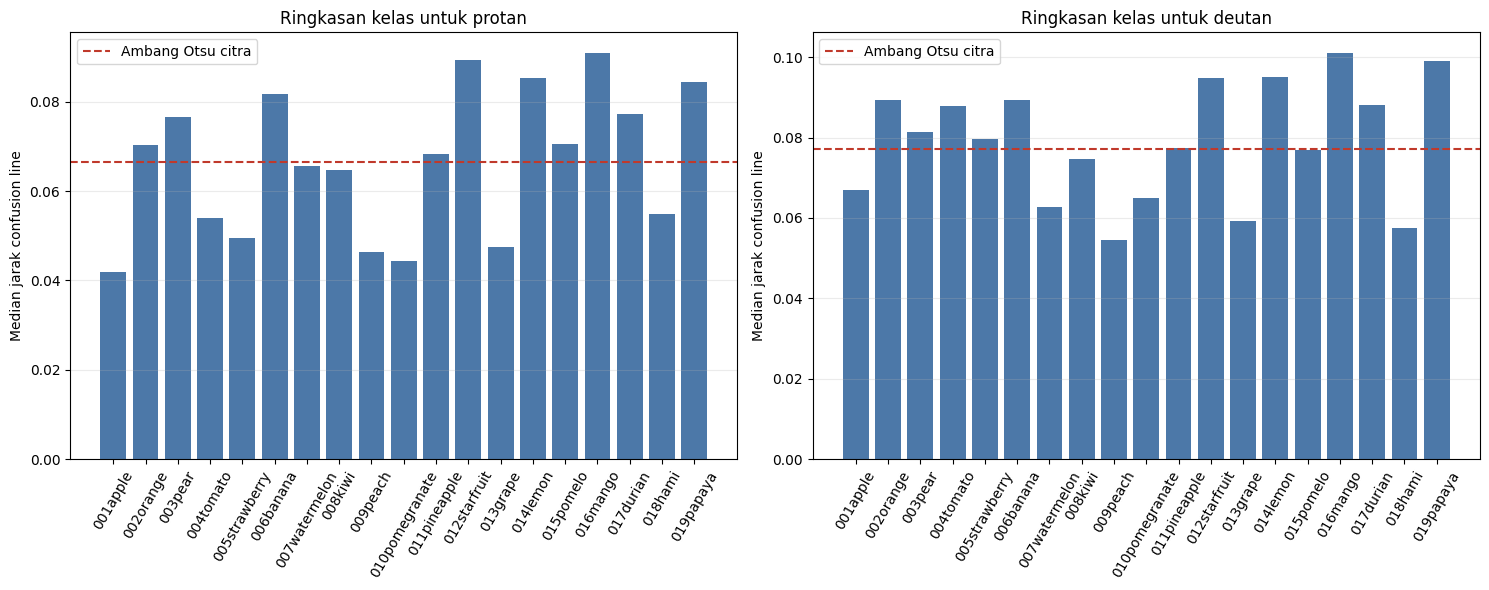

Protan images: 456
Deutan images: 456


In [9]:
required_analysis_state = ['manifest', 'class_confusion_summary', 'ambiguity_thresholds', 'selected_rows_by_cvd']
missing_analysis_state = [name for name in required_analysis_state if name not in globals()]
if missing_analysis_state:
    raise RuntimeError(
        "Jalankan semua sel notebook dari atas. Variabel belum tersedia: "
        + ", ".join(missing_analysis_state)
    )

verification_rows = []
for row in manifest.itertuples(index=False):
    image = cv2.imread(row.output_path, cv2.IMREAD_COLOR)
    verification_rows.append({
        "source_class": row.source_class,
        "output_path": row.output_path,
        "readable": image is not None,
        "width": None if image is None else int(image.shape[1]),
        "height": None if image is None else int(image.shape[0]),
    })
verification = pd.DataFrame(verification_rows)
if not verification["readable"].all() or not (
    (verification["width"] == OUTPUT_SIZE) & (verification["height"] == OUTPUT_SIZE)
).all():
    raise RuntimeError("Verifikasi ukuran atau keterbacaan citra gagal.")
print(f"Seluruh {len(verification)} citra manifest berukuran {OUTPUT_SIZE} x {OUTPUT_SIZE} px.")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, cvd in zip(axes, COPUNCTAL_POINTS):
    metric = f"{cvd}_pair_distance_median"
    summary_column = f"{cvd}_distance_median_across_images"
    values = class_confusion_summary[summary_column]
    ax.bar(class_confusion_summary["source_class"], values, color="#4C78A8")
    ax.axhline(ambiguity_thresholds[cvd], color="#C0392B", linestyle="--", label="Ambang Otsu citra")
    ax.set_title(f"Ringkasan kelas untuk {cvd}")
    ax.set_ylabel("Median jarak confusion line")
    ax.tick_params(axis="x", rotation=60)
    ax.legend()
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_line_class_summary.png", dpi=180, bbox_inches="tight")
plt.show()
print(f"Protan images: {len(selected_rows_by_cvd['protan'])}")
print(f"Deutan images: {len(selected_rows_by_cvd['deutan'])}")
